# Chapter 5 — Classification

**Book:** Practical Statistics for Data Scientists, 2nd Edition

**Name:** Rainaldi Pakpahan
**NIM:** 101032300084
**Class:** TK 47-04

**Name:** Firdaus Arif Ramadhani
**NIM:** 101032300131
**Class:** TK 47-04

Notebook ini mengikuti urutan topik utama Chapter 5 dalam buku karya Peter Bruce, Andrew Bruce, dan Peter Gedeck. Penjelasan diberikan per subtopik secara terperinci. Notebook terdiri dari dua bagian:

- **Bagian A** mereproduksi contoh utama buku memakai data pinjaman (Lending Club) dari repository resmi buku. Bagian ini mengunduh data dari GitHub.
- **Bagian B** memakai dataset yang tersedia dalam scikit-learn sebagai contoh tambahan, sehingga dapat dijalankan di Google Colab tanpa unduhan data eksternal.

Hasil numerik dapat sedikit berbeda sesuai versi pustaka.

## Bagian A — Reproduksi Contoh Buku (Data Pinjaman)

Bagian ini mereproduksi contoh utama Chapter 5 memakai data pinjaman Lending Club dari repository resmi buku. Tiga dataset dipakai:

- `loan_data.csv.gz`: 45,342 pinjaman dengan jumlah pinjaman lunas (`paid off`) dan gagal bayar (`default`) yang sama banyak. Dipakai untuk Naive Bayes dan regresi logistik.
- `loan3000.csv`: sampel 3,000 pinjaman dengan dua prediktor numerik. Dipakai untuk LDA.
- `full_train_set.csv.gz`: 119,987 pinjaman dengan proporsi gagal bayar hanya sekitar 19%. Dipakai untuk strategi data tidak seimbang.

Target klasifikasinya adalah apakah sebuah pinjaman gagal bayar (`default`) atau lunas (`paid off`).

In [1]:
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

REPO_DIR = Path("/content/practical-statistics-for-data-scientists")
REPO_URL = "https://github.com/gedeck/practical-statistics-for-data-scientists.git"

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True
    )

DATA_DIR = REPO_DIR / "data"

loan_data = pd.read_csv(DATA_DIR / "loan_data.csv.gz")
loan3000 = pd.read_csv(DATA_DIR / "loan3000.csv")

print("loan_data :", loan_data.shape)
print("loan3000  :", loan3000.shape)
print()
print(loan_data["outcome"].value_counts())

loan_data : (45342, 21)
loan3000  : (3000, 6)

outcome
default     22671
paid off    22671
Name: count, dtype: int64


### A.1 Naive Bayes

Naive Bayes menghitung probabilitas setiap kelas dengan aturan Bayes dan asumsi bahwa prediktor saling bebas bersyarat pada kelas. Pada contoh buku, prediktornya kategorikal: tujuan pinjaman (`purpose_`), status kepemilikan rumah (`home_`), dan lama bekerja (`emp_len_`).

`MultinomialNB` di scikit-learn membutuhkan masukan numerik, sehingga prediktor diubah menjadi variabel dummy. Parameter `alpha` sangat kecil (tanpa smoothing) dan `fit_prior=False` (prior seragam) dipakai agar hasilnya sama dengan contoh buku. Prediksi dibuat untuk satu pinjaman, yaitu baris 146.

In [2]:
predictors = ["purpose_", "home_", "emp_len_"]

X_nb = pd.get_dummies(loan_data[predictors], prefix="", prefix_sep="", dtype=int)
y_nb = loan_data["outcome"]

naive_model = MultinomialNB(alpha=1e-10, fit_prior=False)
naive_model.fit(X_nb, y_nb)

new_loan = X_nb.loc[146:146, :]

print("Pinjaman baru (baris 146):", loan_data.loc[146, predictors].to_dict())
print("Kelas prediksi           :", naive_model.predict(new_loan)[0])
print()
print(pd.DataFrame(naive_model.predict_proba(new_loan), columns=naive_model.classes_).round(3))
print(f"\nAkurasi pada data latih  : {naive_model.score(X_nb, y_nb):.3f}")

Pinjaman baru (baris 146): {'purpose_': 'small_business', 'home_': 'MORTGAGE', 'emp_len_': ' > 1 Year'}
Kelas prediksi           : default

   default  paid off
0    0.654     0.346

Akurasi pada data latih  : 0.542


**Interpretasi hasil:** Naive Bayes memprediksi `default` untuk pinjaman baris 146 (tujuan `small_business`, status rumah `MORTGAGE`, bekerja lebih dari 1 tahun) dengan probabilitas 0.654, sedangkan `paid off` 0.346. Hasil ini sama dengan contoh buku. Pinjaman untuk usaha kecil memang berisiko lebih tinggi: koefisien `small_business` pada regresi logistik di bagian A.3 adalah yang terbesar.

Akurasi pada data latih hanya 0.542, sedikit di atas 0.5 yang diperoleh dengan menebak pada data yang seimbang. Tiga prediktor kategorikal ini hanya sedikit informatif tentang gagal bayar, dan asumsi independensi antarprediktor juga hanya pendekatan, sehingga model sederhana ini tidak banyak membantu.

### A.2 Linear Discriminant Analysis (LDA)

LDA mencari kombinasi linear prediktor yang paling baik memisahkan kelas. Contoh buku memakai `loan3000` dengan dua prediktor numerik, yaitu `borrower_score` dan `payment_inc_ratio` (rasio cicilan terhadap pendapatan). Karena hanya ada dua prediktor, batas keputusan LDA dapat digambar sebagai garis lurus pada diagram sebar.

In [3]:
X_lda = loan3000[["borrower_score", "payment_inc_ratio"]]
y_lda = loan3000["outcome"]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X_lda, y_lda)

scalings = pd.Series(loan_lda.scalings_.ravel(), index=X_lda.columns)
lda_probability = pd.DataFrame(loan_lda.predict_proba(X_lda), columns=loan_lda.classes_)

print("Koefisien diskriminan (scalings):")
print(scalings.round(4))
print(f"\nAkurasi pada data latih: {loan_lda.score(X_lda, y_lda):.3f}")
print("\nProbabilitas 5 pinjaman pertama:")
print(lda_probability.head().round(3))

Koefisien diskriminan (scalings):
borrower_score       7.1782
payment_inc_ratio   -0.0997
dtype: float64

Akurasi pada data latih: 0.629

Probabilitas 5 pinjaman pertama:
   default  paid off
0    0.554     0.446
1    0.559     0.441
2    0.273     0.727
3    0.506     0.494
4    0.610     0.390


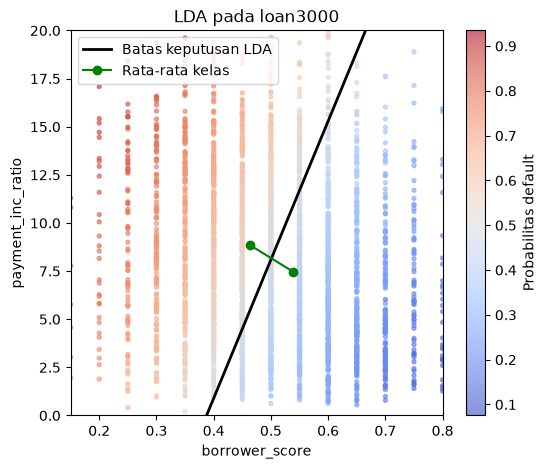

In [4]:
center = loan_lda.means_.mean(axis=0)

slope = -scalings["borrower_score"] / scalings["payment_inc_ratio"]
intercept = center[1] - center[0] * slope

x_at_0 = (0 - intercept) / slope
x_at_20 = (20 - intercept) / slope

fig, ax = plt.subplots(figsize=(6, 5))

points = ax.scatter(
    loan3000["borrower_score"],
    loan3000["payment_inc_ratio"],
    c=lda_probability["default"],
    cmap="coolwarm",
    s=8,
    alpha=0.6
)

ax.plot((x_at_0, x_at_20), (0, 20), color="black", linewidth=2, label="Batas keputusan LDA")
ax.plot(*loan_lda.means_.T, marker="o", color="green", label="Rata-rata kelas")

ax.set_xlim(0.15, 0.8)
ax.set_ylim(0, 20)
ax.set_xlabel("borrower_score")
ax.set_ylabel("payment_inc_ratio")
ax.set_title("LDA pada loan3000")
ax.legend()

fig.colorbar(points, label="Probabilitas default")
plt.show()

**Interpretasi hasil:** Koefisien diskriminan `borrower_score` (7.1782) jauh lebih besar dalam nilai mutlak daripada `payment_inc_ratio` (-0.0997). Perbandingan ini perlu hati-hati karena skala kedua variabel berbeda (`borrower_score` berkisar antara 0 dan 1, sedangkan `payment_inc_ratio` mencapai 20). Arahnya jelas: `borrower_score` yang tinggi mengarah ke `paid off` dan `payment_inc_ratio` yang tinggi mengarah ke `default`. Nilainya hampir sama dengan contoh buku (7.1758 dan -0.0997).

Pada diagram, batas keputusan LDA berupa garis lurus yang memisahkan wilayah `default` (merah, `borrower_score` rendah) dari wilayah `paid off` (biru). Garis ini hampir tegak sehingga `borrower_score` lebih menentukan keputusan daripada `payment_inc_ratio`. Akurasi pada data latih 0.629: LDA hanya memisahkan kedua kelas secara parsial karena banyak pinjaman `default` dan `paid off` yang saling bertumpuk.

### A.3 Regresi Logistik dan Generalized Linear Model

Regresi logistik memodelkan log-odds (logit) dari kejadian `default` sebagai kombinasi linear prediktor. Model dipasang pada `loan_data` dengan lima prediktor: `payment_inc_ratio`, `purpose_`, `home_`, `emp_len_`, dan `borrower_score`. Variabel kategorikal diubah menjadi dummy dengan satu kategori acuan yang dibuang.

`LogisticRegression` di scikit-learn memakai regularisasi L2 secara default. Nilai `C` yang sangat besar membuat regularisasi praktis hilang sehingga koefisiennya sama dengan hasil buku. Sebagai pembanding dipakai `statsmodels` (GLM dengan keluarga binomial) yang juga memberikan standard error dan p-value untuk setiap koefisien.

In [5]:
predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_", "borrower_score"]

X_logit = pd.get_dummies(loan_data[predictors], prefix="", prefix_sep="", drop_first=True, dtype=int)
y_logit = (loan_data["outcome"] == "default").astype(int)

logit_reg = LogisticRegression(C=1e42, solver="liblinear")
logit_reg.fit(X_logit, y_logit)

glm_result = sm.GLM(y_logit, sm.add_constant(X_logit), family=sm.families.Binomial()).fit()

glm_table = glm_result.summary2().tables[1][["Coef.", "Std.Err.", "z", "P>|z|"]]
glm_table["Odds ratio"] = np.exp(glm_table["Coef."])

print(glm_table.round(4))

max_difference = np.abs(glm_result.params.drop("const").to_numpy() - logit_reg.coef_[0]).max()
print(f"\nSelisih koefisien terbesar antara scikit-learn dan statsmodels: {max_difference:.5f}")

                     Coef.  Std.Err.        z   P>|z|  Odds ratio
const               1.6381    0.0737  22.2240  0.0000      5.1453
payment_inc_ratio   0.0797    0.0025  32.0581  0.0000      1.0830
borrower_score     -4.6126    0.0836 -55.2030  0.0000      0.0099
debt_consolidation  0.2494    0.0276   9.0305  0.0000      1.2832
home_improvement    0.4077    0.0466   8.7471  0.0000      1.5034
major_purchase      0.2296    0.0537   4.2775  0.0000      1.2581
medical             0.5105    0.0868   5.8825  0.0000      1.6661
other               0.6207    0.0394  15.7384  0.0000      1.8602
small_business      1.2153    0.0633  19.1924  0.0000      3.3712
OWN                 0.0483    0.0380   1.2706  0.2039      1.0495
RENT                0.1573    0.0212   7.4199  0.0000      1.1704
 > 1 Year          -0.3567    0.0526  -6.7791  0.0000      0.7000

Selisih koefisien terbesar antara scikit-learn dan statsmodels: 0.00045


**Interpretasi hasil:** Pada regresi logistik, koefisien positif berarti prediktor menaikkan peluang `default`, dan odds ratio adalah `exp(koefisien)`. Hasil utamanya:

- `payment_inc_ratio` (koefisien 0.0797; odds ratio 1.083): setiap kenaikan 1 pada rasio cicilan terhadap pendapatan menaikkan odds gagal bayar sekitar 8.3%.
- `borrower_score` (koefisien -4.6126; odds ratio 0.0099): kenaikan 1 unit (seluruh rentang 0 sampai 1) menurunkan odds hampir 99%. Untuk kenaikan 0.1, odds turun sekitar 37% (exp(-0.4613) = 0.63).
- Kategori acuan adalah `credit_card`, `MORTGAGE`, dan bekerja kurang dari 1 tahun. Dibandingkan `credit_card`, pinjaman `small_business` memiliki odds gagal bayar 3.37 kali lebih besar, `other` 1.86 kali, dan `medical` 1.67 kali. Bekerja lebih dari 1 tahun menurunkan odds sekitar 30% (odds ratio 0.70).
- Semua koefisien signifikan dengan p-value di bawah 0.0001, kecuali `OWN` (p-value 0.2039) yang tidak berbeda nyata dari acuan `MORTGAGE`.

Koefisien scikit-learn dan statsmodels hampir identik (selisih terbesar 0.00045). Besarnya sama dengan hasil buku, hanya tandanya berkebalikan karena di sini kelas positifnya `default`, sedangkan scikit-learn pada contoh buku memodelkan `paid off`. Koefisien bukan bukti sebab-akibat, terutama karena beberapa prediktor saling berkaitan. Perlu diingat juga bahwa `borrower_score` pada dataset adalah skor KNN yang dihitung pada data yang sama (lihat Chapter 6, bagian A.3), sehingga koefisiennya yang sangat besar kemungkinan terlalu optimis.

In [6]:
default_probability = logit_reg.predict_proba(X_logit)[:, 1]

print(pd.Series(default_probability, name="P(default)").describe().round(3))

count    45342.000
mean         0.500
std          0.167
min          0.063
25%          0.373
50%          0.498
75%          0.624
max          0.971
Name: P(default), dtype: float64


**Interpretasi hasil:** Probabilitas `default` berkisar dari 0.063 sampai 0.971 dengan rata-rata 0.500, sesuai proporsi kelas yang seimbang. Separuh pinjaman berada pada rentang 0.373 sampai 0.624, sehingga untuk sebagian besar pinjaman model tidak terlalu yakin. Hal ini wajar karena prediktornya hanya mampu memisahkan kelas secara terbatas (lihat AUC pada bagian A.5).

### A.4 Confusion Matrix, Precision, Recall, dan Specificity

Probabilitas diubah menjadi kelas dengan ambang 0.5: pinjaman diprediksi `default` bila peluangnya minimal 0.5. Kelas `default` diperlakukan sebagai kelas positif. Seperti pada buku, evaluasi di sini dilakukan pada data yang sama dengan data pelatihan sehingga hasilnya cenderung lebih optimistis daripada kinerja pada pinjaman baru.

In [7]:
predicted_class = (default_probability >= 0.5).astype(int)

cm = confusion_matrix(y_logit, predicted_class)
tn, fp, fn, tp = cm.ravel()

print(pd.DataFrame(
    cm,
    index=["Aktual paid off", "Aktual default"],
    columns=["Prediksi paid off", "Prediksi default"]
))

print(f"\nAkurasi     : {accuracy_score(y_logit, predicted_class):.4f}")
print(f"Precision   : {tp / (tp + fp):.4f}")
print(f"Recall      : {tp / (tp + fn):.4f}")
print(f"Specificity : {tn / (tn + fp):.4f}")

                 Prediksi paid off  Prediksi default
Aktual paid off              14522              8149
Aktual default                8334             14337

Akurasi     : 0.6365
Precision   : 0.6376
Recall      : 0.6324
Specificity : 0.6406


**Interpretasi hasil:** Dari 22,671 pinjaman `default`, 14,337 terdeteksi dengan benar (recall 0.6324) dan 8,334 terlewat. Dari 22,671 pinjaman `paid off`, 14,522 diprediksi benar (specificity 0.6406) dan 8,149 salah diprediksi `default`. Precision 0.6376 berarti sekitar 64% pinjaman yang diprediksi `default` memang gagal bayar. Akurasi keseluruhan adalah 0.6365. Seluruh angka ini sama dengan contoh buku.

Karena prediktornya lemah, model salah pada sekitar sepertiga pinjaman. Karena kedua kelas seimbang, precision, recall, dan specificity berada pada kisaran yang sama (0.63 sampai 0.64). Perhitungan ini dilakukan pada data latih sehingga kinerja pada pinjaman baru kemungkinan sedikit lebih rendah.

### A.5 ROC Curve dan AUC

Kurva ROC menunjukkan pertukaran antara recall dan specificity ketika ambang probabilitas diubah dari rendah ke tinggi. Sumbu specificity digambar terbalik (1 ke 0) seperti pada buku. AUC adalah luas di bawah kurva: 1 untuk pemisahan sempurna dan 0.5 untuk tebakan acak.

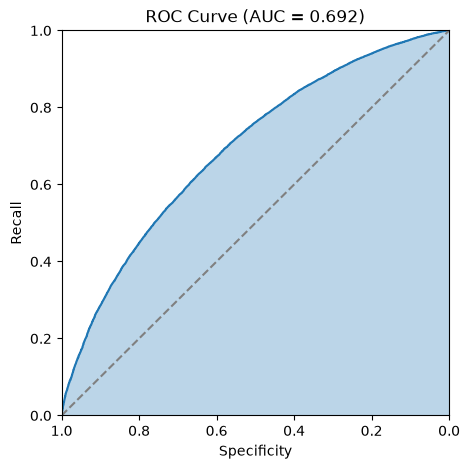

Recall minimal 0.5: specificity 0.761 (ambang 0.562)
Recall minimal 0.7: specificity 0.571 (ambang 0.467)
Recall minimal 0.9: specificity 0.287 (ambang 0.341)


In [8]:
fpr, tpr, thresholds = roc_curve(y_logit, default_probability)
auc_value = roc_auc_score(y_logit, default_probability)

plt.figure(figsize=(5, 5))

plt.plot(1 - fpr, tpr)
plt.plot((1, 0), (0, 1), linestyle="--", color="grey")
plt.fill_between(1 - fpr, 0, tpr, alpha=0.3)

plt.xlim(1, 0)
plt.ylim(0, 1)
plt.xlabel("Specificity")
plt.ylabel("Recall")
plt.title(f"ROC Curve (AUC = {auc_value:.3f})")

plt.show()

for target_recall in (0.5, 0.7, 0.9):
    i = np.argmax(tpr >= target_recall)
    print(f"Recall minimal {target_recall}: specificity {1 - fpr[i]:.3f} (ambang {thresholds[i]:.3f})")

**Interpretasi hasil:** AUC sebesar 0.692 hanya sedikit di atas 0.5 (tebakan acak) dan jauh dari 1, sehingga kemampuan model memisahkan `default` dari `paid off` tergolong terbatas. Nilai ini sama dengan contoh buku. Kurva berada di atas garis diagonal pada seluruh rentang, artinya model lebih baik daripada tebakan acak pada ambang mana pun.

Kurva juga memperlihatkan pertukaran antara recall dan specificity: untuk menjaring 50% pinjaman `default`, specificity masih 0.761, tetapi untuk menjaring 90% specificity turun menjadi 0.287, artinya sebagian besar pinjaman baik ikut diprediksi `default`. Ambang yang dipilih sebaiknya mengikuti biaya kesalahan, bukan hanya nilai AUC.

### A.6 Data Tidak Seimbang: Pembobotan, Undersampling, dan Oversampling

Pada `full_train_set`, pinjaman gagal bayar hanya sekitar 19% dari seluruh pinjaman. Model yang dilatih langsung pada data seperti ini cenderung hampir selalu memprediksi kelas mayoritas. Tiga strategi dibandingkan:

- **Pembobotan (up-weighting):** observasi `default` diberi bobot lebih besar, yaitu 1 dibagi proporsi `default`.
- **Undersampling:** pinjaman `paid off` dikurangi secara acak hingga jumlahnya sama dengan `default`.
- **Oversampling:** pinjaman `default` digandakan secara acak (dengan pengembalian) hingga jumlahnya sama dengan `paid off`.

Penyeimbangan hanya dilakukan pada data pelatihan. Seluruh strategi dievaluasi pada data uji dengan proporsi kelas asli (25% dari data, stratified).

In [9]:
full_train_set = pd.read_csv(DATA_DIR / "full_train_set.csv.gz")

print("Jumlah pinjaman      :", len(full_train_set))
print(f"Pinjaman gagal bayar : {100 * (full_train_set['outcome'] == 'default').mean():.2f}%")

predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_", "dti", "revol_bal", "revol_util"]

X_full = pd.get_dummies(full_train_set[predictors], prefix="", prefix_sep="", drop_first=True, dtype=int)
y_full = (full_train_set["outcome"] == "default").astype(int)

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.25,
    stratify=y_full,
    random_state=42
)

print(f"Proporsi default pada data latih : {y_train_full.mean():.4f}")
print(f"Proporsi default pada data uji   : {y_test_full.mean():.4f}")

Jumlah pinjaman      : 119987
Pinjaman gagal bayar : 18.89%


Proporsi default pada data latih : 0.1889
Proporsi default pada data uji   : 0.1890


In [10]:
rng = np.random.default_rng(42)

index_majority = np.flatnonzero(y_train_full == 0)
index_minority = np.flatnonzero(y_train_full == 1)

undersample_index = np.r_[
    rng.choice(index_majority, size=len(index_minority), replace=False),
    index_minority
]

oversample_index = np.r_[
    np.arange(len(y_train_full)),
    rng.choice(index_minority, size=len(index_majority) - len(index_minority), replace=True)
]

default_weight = 1 / y_train_full.mean()
print(f"Bobot observasi default: {default_weight:.2f}\n")

strategies = {
    "Tanpa penyeimbangan": (X_train_full, y_train_full, None),
    "Pembobotan": (X_train_full, y_train_full, np.where(y_train_full == 1, default_weight, 1)),
    "Undersampling": (X_train_full.iloc[undersample_index], y_train_full.iloc[undersample_index], None),
    "Oversampling": (X_train_full.iloc[oversample_index], y_train_full.iloc[oversample_index], None),
}

rows = []

for name, (X_fit, y_fit, weight) in strategies.items():
    model = LogisticRegression(C=1e42, solver="liblinear")
    model.fit(X_fit, y_fit, sample_weight=weight)
    prediction = model.predict(X_test_full)

    rows.append({
        "Strategi": name,
        "Data latih": len(y_fit),
        "Diprediksi default (%)": 100 * prediction.mean(),
        "Recall default": recall_score(y_test_full, prediction),
        "Precision default": precision_score(y_test_full, prediction, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_test_full, prediction),
        "Akurasi": accuracy_score(y_test_full, prediction),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

Bobot observasi default: 5.29



           Strategi  Data latih  Diprediksi default (%)  Recall default  Precision default  Balanced accuracy  Akurasi
Tanpa penyeimbangan       89990                   0.693           0.015              0.404              0.505    0.810
         Pembobotan       89990                  61.299           0.755              0.233              0.588    0.484
      Undersampling       34006                  42.804           0.593              0.262              0.602    0.607
       Oversampling      145974                  42.338           0.592              0.264              0.604    0.611


**Interpretasi hasil:** Tanpa penyeimbangan, model hampir tidak pernah memprediksi `default`: hanya 0.69% pinjaman uji yang diprediksi gagal bayar dan recall-nya 0.015. Akurasi 0.810 tampak baik, tetapi hanya mendekati proporsi `paid off` (81.1%); balanced accuracy 0.505 menunjukkan model tidak lebih baik daripada tebakan.

Ketiga strategi penyeimbangan mengubah hal ini. Recall `default` naik menjadi 0.755 (pembobotan), 0.593 (undersampling), dan 0.592 (oversampling), sedangkan balanced accuracy naik menjadi 0.588, 0.602, dan 0.604. Harganya adalah precision yang turun (0.233 sampai 0.264) dan akurasi yang turun (0.484 sampai 0.611), karena model kini memprediksi `default` pada 42% sampai 61% pinjaman padahal hanya 19% yang benar-benar gagal bayar. Pembobotan menggeser keputusan paling jauh sehingga recall-nya tertinggi tetapi akurasinya terendah.

Undersampling dan oversampling memberi hasil yang hampir identik. Undersampling hanya memakai 34,006 data latih karena membuang sebagian besar `paid off`, sedangkan oversampling memakai 145,974 data tetapi hanya menggandakan `default` sehingga tidak menambah informasi baru. Pemilihan strategi bergantung pada biaya kesalahan: bila gagal bayar yang terlewat jauh lebih mahal daripada pinjaman baik yang ditolak, recall yang lebih tinggi layak dibayar dengan precision yang lebih rendah.

## Bagian B — Contoh Tambahan (Dataset Breast Cancer, scikit-learn)

Bagian berikut memakai dataset breast cancer bawaan scikit-learn sebagai contoh tambahan. Dataset ini tersedia secara offline sehingga bagian ini dapat dijalankan tanpa unduhan data.

## Persiapan Data Klasifikasi

Klasifikasi memperkirakan kategori, bukan nilai kontinu. Contoh berikut menggunakan data kanker payudara bawaan scikit-learn; label 1 berarti *benign*, sedangkan label 0 berarti *malignant*. Pemisahan data dilakukan sebelum model dilatih.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

raw = load_breast_cancer(as_frame=True)
X, y = raw.data, raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print('Data:', X.shape, 'Train:', X_train.shape, 'Test:', X_test.shape)
print('Distribusi kelas:', y.value_counts().to_dict())

Data: (569, 30) Train: (426, 30) Test: (143, 30)
Distribusi kelas: {1: 357, 0: 212}


**Interpretasi:** Kelas pada dataset tidak memiliki jumlah observasi yang sama. `stratify=y` menjaga proporsi kelas tetap serupa pada data latih dan data uji, sehingga evaluasi lebih representatif.

## Naive Bayes

Naive Bayes menghitung probabilitas kelas dengan aturan Bayes dan asumsi bahwa fitur saling bebas secara kondisional terhadap kelas. Asumsi ini jarang sempurna, tetapi model sering bekerja baik sebagai pembanding awal.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [12]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB().fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
print('Akurasi Naive Bayes:', round(accuracy_score(y_test, nb_pred), 3))
print('Probabilitas untuk 3 observasi pertama: ', nb_model.predict_proba(X_test.iloc[:3]).round(3))

Akurasi Naive Bayes: 0.937
Probabilitas untuk 3 observasi pertama:  [[0. 1.]
 [1. 0.]
 [0. 1.]]


**Interpretasi:** `predict_proba()` menghasilkan dua peluang kelas per observasi yang totalnya satu. Gaussian Naive Bayes menggunakan distribusi normal untuk setiap fitur numerik dalam masing-masing kelas; hasilnya menjadi baseline sebelum mencoba model lain.

## Discriminant Analysis — LDA

Linear Discriminant Analysis (LDA) memodelkan distribusi fitur untuk setiap kelas, dengan asumsi matriks kovarians bersama. Dari sini dibentuk batas keputusan linear yang membedakan kelas.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [13]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda_model = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis())
lda_model.fit(X_train, y_train)
lda_pred = lda_model.predict(X_test)
print('Akurasi LDA:', round(accuracy_score(y_test, lda_pred), 3))
print('Prediksi awal:', lda_pred[:10])

Akurasi LDA: 0.951
Prediksi awal: [1 0 1 1 0 0 0 0 0 1]


**Interpretasi:** Akurasi menunjukkan proporsi label yang benar. LDA menggunakan hubungan antarf fitur melalui kovarians, berbeda dengan asumsi independensi fitur pada Naive Bayes.

## Logistic Regression dan Logit

Regresi logistik menghasilkan peluang kelas melalui fungsi sigmoid. Nilai logit adalah log dari *odds*; koefisien merepresentasikan perubahan log-odds ketika sebuah prediktor naik satu satuan dan prediktor lain tetap.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [14]:
from sklearn.linear_model import LogisticRegression
logit_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
logit_model.fit(X_train, y_train)
logit_prob = logit_model.predict_proba(X_test)[:, 1]
logit_pred = logit_model.predict(X_test)
print('Akurasi Logistic Regression:', round(accuracy_score(y_test, logit_pred), 3))
print('Peluang kelas benign untuk 5 kasus:', np.round(logit_prob[:5], 3))

Akurasi Logistic Regression: 0.986
Peluang kelas benign untuk 5 kasus: [0.969 0.    0.559 0.939 0.175]


**Interpretasi:** Probabilitas memberikan informasi yang lebih rinci daripada label 0/1. Batas klasifikasi standar 0,5 dapat digeser jika kesalahan pada salah satu kelas memiliki konsekuensi lebih besar.

## Koefisien dan Odds Ratio

Interpretasi koefisien perlu memperhatikan skala fitur. Karena seluruh prediktor distandardisasi, odds ratio di bawah menjelaskan perubahan odds dari kenaikan satu simpangan baku fitur.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [15]:
coef = logit_model.named_steps['logisticregression'].coef_[0]
summary = pd.DataFrame({'fitur': X.columns, 'koefisien': coef, 'odds_ratio': np.exp(coef)})
print(summary.reindex(summary.koefisien.abs().sort_values(ascending=False).index).head(8).round(3).to_string(index=False))

               fitur  koefisien  odds_ratio
       worst texture     -1.250       0.286
        radius error     -1.070       0.343
      worst symmetry     -0.957       0.384
worst concave points     -0.942       0.390
          area error     -0.941       0.390
          worst area     -0.926       0.396
        worst radius     -0.917       0.400
     worst concavity     -0.797       0.451


**Interpretasi:** Odds ratio di atas 1 mengindikasikan kenaikan odds kelas 1, sedangkan di bawah 1 menunjukkan penurunan odds kelas 1. Koefisien bukan bukti sebab-akibat; fitur yang saling berkorelasi juga memengaruhi nilainya.

## Confusion Matrix

Akurasi saja dapat menyembunyikan jenis kesalahan. *Confusion matrix* menampilkan prediksi benar dan salah per kelas; urutan label pada tabel ini adalah 0 (malignant) lalu 1 (benign).

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

          Prediksi 0  Prediksi 1
Aktual 0          52           1
Aktual 1           1          89


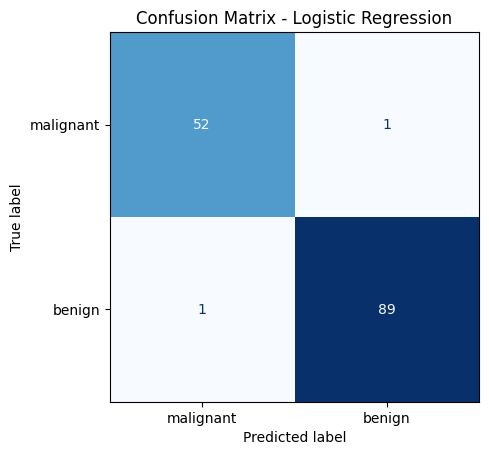

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test, logit_pred)
print(pd.DataFrame(cm,index=['Aktual 0','Aktual 1'],columns=['Prediksi 0','Prediksi 1']))
ConfusionMatrixDisplay(cm,display_labels=['malignant','benign']).plot(cmap='Blues',colorbar=False)
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

**Interpretasi:** Angka di diagonal utama adalah prediksi yang benar, sementara sel di luar diagonal menunjukkan kesalahan. Dalam aplikasi medis, kesalahan mendeteksi kasus malignant sebagai benign harus diperhatikan secara khusus.

## Precision, Recall, Specificity, dan F1

Precision mengukur ketepatan prediksi positif; recall mengukur berapa banyak kasus positif ditemukan. Specificity berfokus pada kelas negatif. F1 merangkum precision dan recall.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score
print(classification_report(y_test, logit_pred, target_names=['malignant','benign']))
tn, fp, fn, tp = cm.ravel()
print('Specificity untuk kelas benign:',round(tn/(tn+fp),3))
print('Recall untuk kelas benign:',round(tp/(tp+fn),3))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

Specificity untuk kelas benign: 0.981
Recall untuk kelas benign: 0.989


**Interpretasi:** Precision, recall, dan specificity menilai sisi berbeda dari kesalahan klasifikasi. Pemilihan metrik harus mengikuti kelas mana yang diperlakukan sebagai positif dan konsekuensi kesalahan yang paling penting.

## ROC Curve dan AUC

Kurva ROC menampilkan *true positive rate* terhadap *false positive rate* ketika ambang probabilitas berubah. AUC mengukur kemampuan model mengurutkan contoh positif lebih tinggi daripada negatif.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

ROC AUC: 0.998


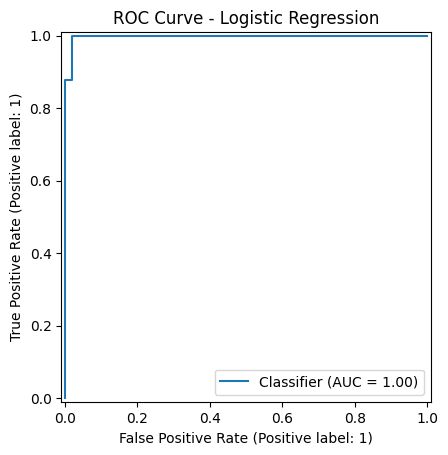

In [18]:
from sklearn.metrics import RocCurveDisplay
auc = roc_auc_score(y_test, logit_prob)
print('ROC AUC:',round(auc,3))
RocCurveDisplay.from_predictions(y_test,logit_prob)
plt.title('ROC Curve - Logistic Regression')
plt.show()

**Interpretasi:** AUC mendekati 1 berarti pemisahan peringkat antarkelas sangat baik, sedangkan mendekati 0,5 mirip tebakan acak. AUC tidak memberi tahu ambang keputusan terbaik untuk konteks penggunaan tertentu.

## Class Imbalance dan Resampling

Ketika kelas positif jarang muncul, model dapat memperoleh akurasi tinggi hanya dengan menebak kelas mayoritas. Teknik yang dibahas buku termasuk undersampling, oversampling, dan pembobotan kelas.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [19]:
from sklearn.datasets import make_classification
from sklearn.metrics import balanced_accuracy_score, average_precision_score
from sklearn.model_selection import train_test_split
X_imb, y_imb = make_classification(n_samples=1500,n_features=12,n_informative=5,weights=[0.94,0.06],random_state=42)
Xi_tr,Xi_te,yi_tr,yi_te = train_test_split(X_imb,y_imb,stratify=y_imb,test_size=.3,random_state=42)
base = LogisticRegression(max_iter=2000).fit(Xi_tr,yi_tr)
weighted = LogisticRegression(max_iter=2000,class_weight='balanced').fit(Xi_tr,yi_tr)
for name, m in [('Tanpa bobot',base),('Class weight balanced',weighted)]:
 pred=m.predict(Xi_te); prob=m.predict_proba(Xi_te)[:,1]
 print(name, '| accuracy:',round(accuracy_score(yi_te,pred),3),'| recall:',round(recall_score(yi_te,pred),3),'| balanced accuracy:',round(balanced_accuracy_score(yi_te,pred),3),'| average precision:',round(average_precision_score(yi_te,prob),3))

Tanpa bobot | accuracy: 0.951 | recall: 0.321 | balanced accuracy: 0.657 | average precision: 0.584
Class weight balanced | accuracy: 0.847 | recall: 0.75 | balanced accuracy: 0.802 | average precision: 0.544


**Interpretasi:** `class_weight="balanced"` memberi pengaruh lebih besar pada kelas minoritas dan biasanya mengubah kompromi precision–recall. Balanced accuracy dan average precision lebih informatif daripada akurasi biasa pada data yang sangat tidak seimbang.

## Mengubah Decision Threshold

Prediksi probabilitas dapat diubah menjadi keputusan dengan ambang selain 0,5. Penurunan threshold biasanya meningkatkan recall kelas positif, tetapi dapat menambah false positive.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [20]:
for threshold in [0.3,0.5,0.7]:
 pred = (weighted.predict_proba(Xi_te)[:,1] >= threshold).astype(int)
 print(f'Threshold {threshold:.1f}: precision={precision_score(yi_te,pred,zero_division=0):.3f}, recall={recall_score(yi_te,pred):.3f}, F1={f1_score(yi_te,pred):.3f}')

Threshold 0.3: precision=0.178, recall=0.857, F1=0.294
Threshold 0.5: precision=0.253, recall=0.750, F1=0.378
Threshold 0.7: precision=0.378, recall=0.607, F1=0.466


**Interpretasi:** Tidak ada threshold terbaik untuk semua masalah. Threshold sebaiknya dipilih dari data validasi dan biaya kesalahan klasifikasi, bukan berdasarkan hasil data uji saja.

## Pendalaman Subtopik sesuai Struktur Buku

Bagian berikut memperinci konsep-konsep penting yang dibahas di chapter ini. Contoh tambahan menggunakan dataset yang disiapkan pada bagian awal notebook, sehingga setiap pembahasan tetap dapat dijalankan berurutan di Google Colab.

### 1. Mengapa Bayesian Classification Tidak Dihitung Secara Eksak

Pada klasifikasi Bayesian, tujuan kita adalah membandingkan probabilitas setiap kelas setelah melihat kombinasi fitur suatu observasi. Jika jumlah fitur banyak dan masing-masing punya banyak kemungkinan nilai, jumlah kombinasi yang perlu dipelajari meningkat sangat cepat. Mengestimasi distribusi gabungan secara langsung sulit, apalagi apabila jumlah observasi terbatas. Naive Bayes menyederhanakan masalah dengan menganggap fitur saling independen bersyarat pada kelas. Asumsi ini memang kuat, tetapi membuat estimasi jauh lebih praktis.

Contoh berikut menghitung probabilitas posterior sederhana dengan aturan Bayes sebelum menggunakan algoritma klasifikasi yang lebih kompleks.

In [21]:
prior = 0.08
sensitivity = 0.90
false_positive_rate = 0.12
posterior = sensitivity*prior/(sensitivity*prior+false_positive_rate*(1-prior))
print('Prior kelas positif:',round(prior,3))
print('Posterior setelah tes positif:',round(posterior,3))

Prior kelas positif: 0.08
Posterior setelah tes positif: 0.395


**Interpretasi hasil:** Probabilitas setelah tes positif meningkat dibanding prior awal, tetapi tidak langsung menjadi 90%. Hasil tes harus ditafsirkan bersama prevalensi dasar dan peluang false positive. Inilah alasan probabilitas posterior tidak boleh disamakan dengan sensitivitas model.

### 2. Asumsi Independensi pada Naive Bayes

Dalam praktik, beberapa fitur pengukuran memiliki korelasi tinggi. Contohnya, ukuran area dan radius sel dapat bergerak bersama. Gaussian Naive Bayes tetap memakai model probabilitas terpisah untuk masing-masing fitur. Karena itu, hasilnya cukup baik untuk pembanding, tetapi probabilitas keluarannya dapat terlalu yakin ketika asumsi independensi tidak terpenuhi.

Kita membandingkan korelasi dua fitur dengan akurasi Gaussian Naive Bayes tanpa menganggap korelasi sebagai kesalahan implementasi.

In [22]:
print('Korelasi radius–perimeter:',round(X[['mean radius','mean perimeter']].corr().iloc[0,1],3))
print('Akurasi GaussianNB:',round(accuracy_score(y_test, nb_model.predict(X_test)),3))
print('Prior kelas yang dipelajari:',np.round(nb_model.class_prior_,3))

Korelasi radius–perimeter: 0.998
Akurasi GaussianNB: 0.937
Prior kelas yang dipelajari: [0.373 0.627]


**Interpretasi hasil:** Korelasi tinggi memperlihatkan bahwa asumsi bebas bersyarat bukan gambaran sempurna dari fitur dunia nyata. Meskipun demikian, model masih bisa memberikan prediksi yang masuk akal. Akurasi model tidak membuktikan bahwa seluruh asumsi probabilistiknya benar.

### 3. Covariance Matrix dalam Discriminant Analysis

LDA menggunakan informasi hubungan antarfitur melalui matriks kovarians. Elemen diagonal merepresentasikan variansi tiap fitur, sedangkan elemen luar diagonal memperlihatkan pergerakan bersama dua fitur. Dalam LDA, kovarians setiap kelas diasumsikan sama sehingga batas keputusan yang terbentuk linear. Untuk mengilustrasikan bentuk matriks tersebut, kita melihat fitur terpilih sesudah standardisasi.

In [23]:
scaled4 = StandardScaler().fit_transform(X_train.iloc[:,:4])
cov4 = np.cov(scaled4,rowvar=False)
print(pd.DataFrame(cov4,index=X.columns[:4],columns=X.columns[:4]).round(2))

                mean radius  mean texture  mean perimeter  mean area
mean radius            1.00          0.33            1.00       0.99
mean texture           0.33          1.00            0.33       0.32
mean perimeter         1.00          0.33            1.00       0.99
mean area              0.99          0.32            0.99       1.00


**Interpretasi hasil:** Nilai diagonal mendekati satu akibat standardisasi, tetapi elemen selain diagonal tidak otomatis menjadi nol. Matriks ini menunjukkan informasi dependensi yang dapat dipakai oleh pendekatan diskriminan dan tidak ditangani dengan cara sama oleh Naive Bayes.

### 4. Fisher Linear Discriminant

Ide Fisher adalah mencari arah proyeksi yang menghasilkan perbedaan rata-rata antarkelas besar dibanding penyebaran di dalam masing-masing kelas. Untuk masalah dua kelas, cukup satu arah diskriminan. Dengan menampilkan proyeksi hasil LDA, kita dapat melihat apakah distribusi observasi dari kedua kelas cenderung terpisah.

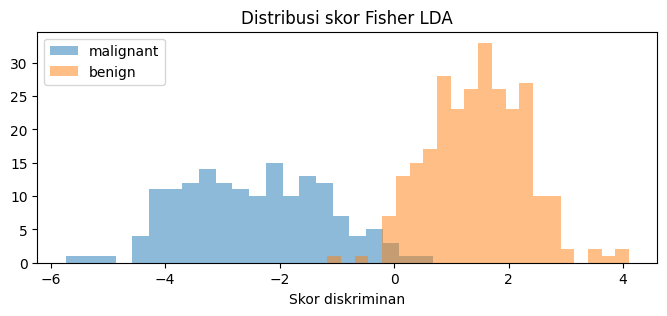

In [24]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
scaler_lda=StandardScaler().fit(X_train)
lda_projection=LinearDiscriminantAnalysis(n_components=1).fit_transform(scaler_lda.transform(X_train),y_train)
plt.figure(figsize=(8,3))
for cls,name in [(0,'malignant'),(1,'benign')]:
 plt.hist(lda_projection[y_train.to_numpy()==cls,0],bins=22,alpha=.5,label=name)
plt.legend();plt.title('Distribusi skor Fisher LDA');plt.xlabel('Skor diskriminan');plt.show()

**Interpretasi hasil:** Jika histogram kedua kelas hanya sedikit bertumpuk, satu skor diskriminan sudah memisahkan banyak observasi. Area tumpang tindih menjelaskan mengapa kesalahan tetap mungkin terjadi. Grafik merupakan proyeksi hasil pelatihan, bukan pengukuran akurasi pada data uji.

### 5. Logistic Response Function (Sigmoid)

Regresi logistik mengubah kombinasi linear prediktor menjadi probabilitas melalui fungsi sigmoid. Berbeda dengan regresi linear, nilai keluaran dibatasi antara nol dan satu. Ketika logit bernilai nol, probabilitasnya 0,5; nilai logit positif meningkatkan peluang kelas 1, dan logit negatif menurunkannya.

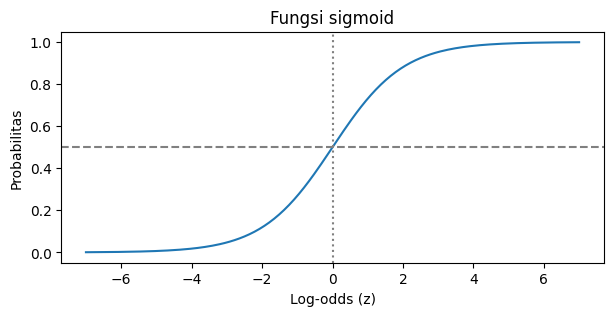

Logit -2 -> 0.119
Logit 0 -> 0.5
Logit 2 -> 0.881


In [25]:
z=np.linspace(-7,7,200)
p=1/(1+np.exp(-z))
plt.figure(figsize=(7,3));plt.plot(z,p);plt.axhline(.5,ls='--',color='gray');plt.axvline(0,ls=':',color='gray')
plt.xlabel('Log-odds (z)');plt.ylabel('Probabilitas');plt.title('Fungsi sigmoid');plt.show()
for zi in [-2,0,2]:print('Logit',zi,'->',round(1/(1+np.exp(-zi)),3))

**Interpretasi hasil:** Perubahan satu unit logit tidak menghasilkan tambahan probabilitas yang tetap. Perubahan paling terasa di sekitar probabilitas 0,5 dan makin kecil pada kedua ujung kurva. Karena itu, koefisien regresi logistik lebih tepat dibahas sebagai perubahan log-odds.

### 6. Generalized Linear Models (GLM)

Buku menjelaskan regresi logistik sebagai salah satu generalized linear model. Komponen utamanya meliputi variabel respons dengan distribusi tertentu, prediktor linear, dan fungsi taut yang menghubungkan nilai harapan respons ke skala linear. Pada regresi logistik biner, fungsi taut yang dipakai adalah logit. Perbedaannya dengan model linear biasa terletak pada bentuk respons dan cara peluang dipetakan.

In [26]:
p_check=np.array([0.10,0.25,0.50,0.75,0.90])
logit_check=np.log(p_check/(1-p_check))
print(pd.DataFrame({'probability':p_check,'logit':logit_check}).round(3).to_string(index=False))

 probability  logit
        0.10 -2.197
        0.25 -1.099
        0.50  0.000
        0.75  1.099
        0.90  2.197


**Interpretasi hasil:** Skala logit berjalan dari minus tak hingga sampai plus tak hingga, berbeda dengan skala probabilitas. Transformasi logit menghasilkan angka negatif untuk peluang kurang dari 0,5 dan positif untuk peluang lebih dari 0,5. Hal ini membuat prediktor linear tetap bisa digunakan dalam model probabilitas.

### 7. Predicted Values: Class versus Probability

Prediksi label dan prediksi probabilitas tidak identik. `predict()` menerapkan aturan keputusan untuk memilih kelas, sedangkan `predict_proba()` menyajikan keyakinan model terhadap dua kelas. Dua kasus dengan label sama dapat mempunyai tingkat ketidakpastian sangat berbeda. Ini penting untuk sistem yang menyediakan tinjauan manual terhadap kasus meragukan.

In [27]:
pred_table=pd.DataFrame({'actual':y_test.to_numpy()[:12], 'predicted':logit_pred[:12], 'probability_benign':logit_prob[:12]})
print(pred_table.round(3).to_string(index=False))

 actual  predicted  probability_benign
      1          1               0.969
      0          0               0.000
      1          1               0.559
      1          1               0.939
      0          0               0.175
      0          0               0.000
      0          0               0.003
      0          0               0.001
      0          0               0.001
      1          1               1.000
      1          1               0.700
      1          1               0.999


**Interpretasi hasil:** Kasus dengan probabilitas mendekati 0,5 secara alami lebih sulit diputuskan daripada probabilitas mendekati nol atau satu. Perbedaan ini tidak terlihat ketika hanya menampilkan kelas prediksi. Probabilitas juga perlu dinilai kalibrasinya sebelum dianggap dapat dipercaya secara operasional.

### 8. Assessing Logistic Regression: Deviance dan Log Loss

Selain akurasi, fungsi kerugian probabilistik mengukur seberapa tepat peluang yang dikeluarkan model. Log loss memberi penalti besar saat model sangat yakin tetapi salah. Maka dua model dengan akurasi sama belum tentu mempunyai kualitas probabilitas yang setara. Pada tugas probabilistik, log loss merupakan pendamping penting ROC-AUC.

In [28]:
from sklearn.metrics import log_loss, brier_score_loss
print('Log loss:',round(log_loss(y_test,logit_prob),4))
print('Brier score:',round(brier_score_loss(y_test,logit_prob),4))
print('Accuracy:',round(accuracy_score(y_test,logit_pred),4))

Log loss: 0.0679
Brier score: 0.0181
Accuracy: 0.986


**Interpretasi hasil:** Log loss dan Brier score lebih kecil berarti lebih baik. Tidak seperti akurasi, kedua metrik memakai besarnya probabilitas, bukan sekadar keputusan kelas akhir. Karena sampel uji relatif terbatas, nilai numerik sebaiknya dibaca sebagai gambaran untuk pembagian data ini.

### 9. Rare Class Problem

Pada dataset tidak seimbang, prediksi mayoritas dapat menghasilkan akurasi tinggi sekalipun tidak pernah mendeteksi kelas langka. Ini disebut masalah rare class. Kita memperlihatkannya dengan baseline yang selalu menebak kelas nol pada dataset sintetis yang telah digunakan sebelumnya.

In [29]:
from sklearn.metrics import balanced_accuracy_score
majority=np.zeros_like(yi_te)
print('Proporsi kelas positif:',round(yi_te.mean(),3))
print('Akurasi selalu mayoritas:',round(accuracy_score(yi_te,majority),3))
print('Recall kelas minoritas:',round(recall_score(yi_te,majority),3))
print('Balanced accuracy:',round(balanced_accuracy_score(yi_te,majority),3))

Proporsi kelas positif: 0.062
Akurasi selalu mayoritas: 0.938
Recall kelas minoritas: 0.0
Balanced accuracy: 0.5


**Interpretasi hasil:** Model mayoritas tampak bagus menurut akurasi karena sebagian besar data memang berasal dari kelas nol. Namun, recall kelas positif nol menunjukkan bahwa tidak ada kasus langka yang terdeteksi. Balanced accuracy membantu memperlihatkan kegagalan ini.

### 10. Precision–Recall Curve

Ketika kelas positif jarang, kurva precision–recall sering lebih informatif daripada ROC. Precision mengukur seberapa banyak prediksi positif yang benar, sedangkan recall mengukur berapa banyak positif aktual ditemukan. Mengubah ambang membuat kedua metrik bergeser dan menimbulkan kompromi yang harus dipertimbangkan.

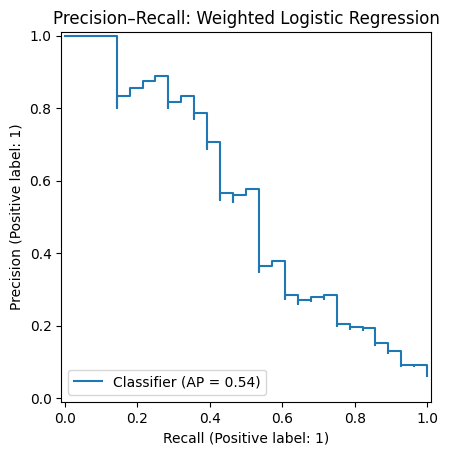

Average precision: 0.544


In [30]:
from sklearn.metrics import PrecisionRecallDisplay,average_precision_score
PrecisionRecallDisplay.from_predictions(yi_te, weighted.predict_proba(Xi_te)[:,1])
plt.title('Precision–Recall: Weighted Logistic Regression');plt.show()
print('Average precision:',round(average_precision_score(yi_te,weighted.predict_proba(Xi_te)[:,1]),3))

**Interpretasi hasil:** Average precision merangkum performa di berbagai tingkat recall dan perlu dibandingkan dengan prevalensi kelas positif. Model yang menjaring lebih banyak positif sering mengorbankan ketepatan prediksi positif. Titik operasi akhir ditentukan oleh kebutuhan kasus nyata, bukan sekadar tampilan kurva.

### 11. Lift dan Pemeringkatan Probabilitas

Lift digunakan ketika model bertujuan memilih kelompok teratas untuk ditindaklanjuti, misalnya pelanggan yang paling mungkin merespons promosi. Kita urutkan seluruh observasi menurut prediksi probabilitas lalu melihat seberapa banyak kelas positif terkumpul pada 20% skor tertinggi. Lift membandingkan tingkat positif pada kelompok pilihan terhadap tingkat positif keseluruhan.

In [31]:
scores=weighted.predict_proba(Xi_te)[:,1]
top_n=max(1,int(.20*len(scores)))
selected=np.argsort(scores)[-top_n:]
top_rate=yi_te[selected].mean()
base_rate=yi_te.mean()
print('Positive rate overall:',round(base_rate,3))
print('Positive rate top 20%:',round(top_rate,3))
print('Lift top 20%:',round(top_rate/base_rate,2))

Positive rate overall: 0.062
Positive rate top 20%: 0.233
Lift top 20%: 3.75


**Interpretasi hasil:** Lift lebih dari satu berarti kelompok dengan skor tertinggi memiliki konsentrasi kasus positif di atas rata-rata populasi uji. Nilai lift tidak sama dengan akurasi; metrik ini berfokus pada kualitas peringkat untuk sejumlah observasi terpilih.

### 12. Undersampling pada Data Tidak Seimbang

Undersampling mengurangi jumlah observasi mayoritas agar lebih seimbang dengan minoritas. Metode ini sederhana tetapi membuang sebagian informasi kelas mayoritas. Untuk mencegah kebocoran informasi, sampling hanya dilakukan pada data pelatihan, bukan data uji. Perbandingan dibuat menggunakan indeks acak yang tetap agar dapat diulang.

In [32]:
rng=np.random.default_rng(42)
idx_major=np.flatnonzero(yi_tr==0)
idx_minor=np.flatnonzero(yi_tr==1)
keep=np.r_[rng.choice(idx_major,size=len(idx_minor),replace=False),idx_minor]
under=LogisticRegression(max_iter=2000).fit(Xi_tr[keep],yi_tr[keep])
print('Sebelum:',np.bincount(yi_tr),'Sesudah:',np.bincount(yi_tr[keep]))
print('Recall undersampling:',round(recall_score(yi_te,under.predict(Xi_te)),3))
print('Precision undersampling:',round(precision_score(yi_te,under.predict(Xi_te),zero_division=0),3))

Sebelum: [985  65] Sesudah: [65 65]
Recall undersampling: 0.821
Precision undersampling: 0.232


**Interpretasi hasil:** Undersampling memperbesar pengaruh kelas minoritas karena rasio kelas pelatihan berubah. Recall bisa meningkat, tetapi ketepatan dan kestabilan dapat berubah karena beberapa contoh mayoritas tidak dipakai. Evaluasi tetap pada data uji dengan prevalensi asli.

### 13. Oversampling pada Data Tidak Seimbang

Berbeda dengan undersampling, oversampling menggandakan observasi kelas minoritas di dalam data pelatihan. Metode ini mempertahankan data mayoritas, tetapi pengulangan data bukan informasi baru. Eksperimen berikut memperlihatkan balancing dengan replacement; data pengujian tetap tidak disentuh.

In [33]:
idx_minor_extra=rng.choice(idx_minor,size=len(idx_major)-len(idx_minor),replace=True)
over_idx=np.r_[np.arange(len(yi_tr)),idx_minor_extra]
over=LogisticRegression(max_iter=2000).fit(Xi_tr[over_idx],yi_tr[over_idx])
print('Komposisi setelah oversampling:',np.bincount(yi_tr[over_idx]))
print('Recall oversampling:',round(recall_score(yi_te,over.predict(Xi_te)),3))
print('Precision oversampling:',round(precision_score(yi_te,over.predict(Xi_te),zero_division=0),3))

Komposisi setelah oversampling: [985 985]
Recall oversampling: 0.75
Precision oversampling: 0.247


**Interpretasi hasil:** Penyeimbangan kelas menambah kesempatan model mempelajari pola minoritas tetapi tidak menjamin performa selalu lebih baik. Jika validasi silang digunakan, langkah oversampling harus dilakukan di dalam setiap fold pelatihan agar evaluasi tidak terlalu optimistis.

### 14. Cost-Based Classification

Beberapa keputusan memiliki biaya salah klasifikasi yang tidak simetris. Contohnya, tidak menemukan kasus positif bisa jauh lebih mahal daripada pemeriksaan tambahan yang ternyata tidak diperlukan. Kita mengilustrasikan biaya false negative dan false positive pada beberapa threshold. Angka biaya hanya contoh analitis, bukan harga atau risiko medis nyata.

In [34]:
from sklearn.metrics import confusion_matrix
prob_cost=weighted.predict_proba(Xi_te)[:,1]
for t in [0.20,0.35,0.50,0.65]:
 tn,fp,fn,tp=confusion_matrix(yi_te,prob_cost>=t).ravel()
 cost=fn*8+fp*1
 print(f'threshold={t:.2f}: FN={fn}, FP={fp}, illustrative cost={cost}')

threshold=0.20: FN=3, FP=151, illustrative cost=175
threshold=0.35: FN=5, FP=94, illustrative cost=134
threshold=0.50: FN=7, FP=62, illustrative cost=118
threshold=0.65: FN=11, FP=36, illustrative cost=124


**Interpretasi hasil:** Threshold dengan biaya ilustratif paling kecil dipengaruhi kuat oleh bobot 8:1 yang ditetapkan. Apabila konsekuensi berubah, threshold terbaik juga bisa berubah. Prosedur sebenarnya membutuhkan estimasi biaya dari konteks dan pemilihan threshold pada set validasi.

### 15. Exploring the Predictions

Analisis akhir tidak hanya merangkum satu skor keseluruhan. Kita juga perlu melihat observasi mana yang diprediksi keliru, berapa besar probabilitasnya, dan apakah kesalahan terkumpul dalam area skor tertentu. Tabel ringkas berikut memperlihatkan kasus salah prediksi yang dapat ditinjau lebih lanjut.

In [35]:
cases=pd.DataFrame({'actual':yi_te,'probability':prob_cost,'predicted':(prob_cost>=.5).astype(int)})
cases['error']=cases.actual!=cases.predicted
print('Jumlah salah prediksi:',cases.error.sum())
print(cases.loc[cases.error].head(10).round(3).to_string(index=False))

Jumlah salah prediksi: 69
 actual  probability  predicted  error
      0        0.768          1   True
      1        0.048          0   True
      0        0.750          1   True
      0        0.624          1   True
      0        0.730          1   True
      0        0.983          1   True
      0        0.521          1   True
      0        0.592          1   True
      0        0.731          1   True
      0        0.668          1   True


**Interpretasi hasil:** Tabel menunjukkan jenis kesalahan dan tingkat keyakinan pada masing-masing kasus. Kesalahan dengan probabilitas yang sangat dekat ke threshold perlu dianalisis berbeda dari kesalahan yang dibuat dengan keyakinan tinggi. Analisis seperti ini membantu mengidentifikasi kebutuhan perbaikan dataset atau kalibrasi model.